# Módulo 8 — Transformada de Fourier
## Seção 8.6 — Transformada Discreta de Fourier (DFT)

**Objetivo.** Deduzir a DFT como projeção em exponenciais complexas ortogonais, compreender a transformada inversa e Parseval discreto, calcular uma DFT manualmente e interpretá-la com `numpy.fft` sem confundir índices, frequências e amplitudes.

**Pré-requisitos:** Seções 8.1–8.5, soma de progressão geométrica, números complexos e operações com arrays NumPy.

**Rastreabilidade.** MORETTIN e TOLOI (2018), v. 1, cap. 13, §13.4, pp. 348–350, eqs. (13.26)–(13.28): análise harmônica discreta e coeficientes; cap. 14, §14.4.1, pp. **367–369**, eq. (14.18): transformada discreta e sua relação com o periodograma. A derivação matricial, a inversa e a comparação com `numpy.fft` são explicações matemáticas/computacionais complementares, utilizando a convenção abaixo. Observe que o livro também pode usar fatores $1/\sqrt N$ e convenções de sinal diferentes ao formular a transformada para análise espectral; **não** identificamos as fórmulas de normalização do NumPy como cópia literal de sua eq. (14.18).

---

### 1. Problema e intuição

A transformada contínua da seção 8.5 integra um sinal observado em tempo contínuo. Porém, dados reais vêm como uma lista de valores, por exemplo $x_0,x_1,\ldots,x_{N-1}$. Precisamos medir quanto uma sequência finita contém das frequências que “cabem” na janela de observação. A DFT projeta o vetor observado sobre $N$ **ondas complexas discretas**; não é necessário supor que os dados são exatamente periódicos, mas a reconstrução da DFT corresponde a uma extensão periódica de comprimento $N$.

### 2. Definição da DFT e da inversa

Para $N$ amostras $x_n$ e $k=0,\ldots,N-1$, adotamos a **convenção do NumPy**, com sinal negativo na análise e fator $1/N$ na reconstrução:

$$\boxed{X_k=\sum_{n=0}^{N-1}x_n\,e^{-i2\pi kn/N}.}$$

A inversa é

$$\boxed{x_n=\frac1N\sum_{k=0}^{N-1}X_k\,e^{i2\pi kn/N}.}$$

**Símbolos:** $n$ é o índice temporal; $k$ o índice de frequência; $N$ o tamanho da amostra; $x_n$ o valor observado; $X_k$ a contribuição complexa da frequência $k/N$ ciclos/amostra. Se o intervalo entre observações é $\Delta t$, a frequência física é $\nu_k=k/(N\Delta t)$ ciclos/unidade de tempo, interpretada módulo $1/\Delta t$ (frequências acima da metade da taxa de amostragem são usualmente representadas como negativas).

### 3. Demonstração da ortogonalidade discreta

Defina $u_k(n)=e^{i2\pi kn/N}$. O produto interno usual de vetores complexos dá

$$\langle u_k,u_\ell\rangle=\sum_{n=0}^{N-1}u_k(n)\overline{u_\ell(n)}=\sum_{n=0}^{N-1}e^{i2\pi(k-\ell)n/N}.$$

Se $k=\ell$ módulo $N$, todos os termos valem $1$, e a soma é $N$. Caso contrário, com $r=e^{i2\pi(k-\ell)/N}\ne1$, a soma geométrica é

$$\sum_{n=0}^{N-1}r^n=\frac{1-r^N}{1-r}=0,$$

porque $r^N=e^{i2\pi(k-\ell)}=1$. Concluímos:

$$\boxed{\sum_{n=0}^{N-1}e^{i2\pi(k-\ell)n/N}=N\,\delta_{k\ell},\quad 0\le k,\ell<N.}$$

É esta propriedade que permite recuperar, sem misturar, os $N$ coeficientes de frequência.

### 4. Demonstração da transformada inversa

Substituindo a definição direta na fórmula inversa proposta,

$$\begin{aligned}
\frac1N\sum_{k=0}^{N-1}X_k e^{i2\pi km/N}
&=\frac1N\sum_{k=0}^{N-1}\sum_{n=0}^{N-1}x_n e^{i2\pi k(m-n)/N}\\
&=\sum_{n=0}^{N-1}x_n\left[\frac1N\sum_{k=0}^{N-1}e^{i2\pi k(m-n)/N}\right]\\
&=\sum_{n=0}^{N-1}x_n\delta_{mn}=x_m.
\end{aligned}$$

A troca de somas é permitida porque as duas são finitas. Isso demonstra a reconstrução exata em aritmética ideal.

### 5. Exemplo numérico feito à mão ($N=4$)

Tome

$$\mathbf x=(x_0,x_1,x_2,x_3)=(1,2,0,-1).$$

Calculamos o primeiro coeficiente:

$$X_0=1+2+0-1=2.$$

Para $k=1$, os fatores são $1,-i,-1,i$:

$$X_1=1+2(-i)+0(-1)+(-1)i=1-3i.$$

Para $k=2$, os fatores são $1,-1,1,-1$:

$$X_2=1-2+0+1=0.$$

Por simetria de sequência real, $X_3=\overline{X_1}=1+3i$. Assim,

$$\boxed{\mathbf X=(2,\ 1-3i,\ 0,\ 1+3i).}$$

Vamos conferir com NumPy e, separadamente, com a definição direta.

In [1]:
import numpy as np
x = np.array([1., 2., 0., -1.])
N = len(x)
X_manual = np.array([sum(x[n]*np.exp(-2j*np.pi*k*n/N) for n in range(N)) for k in range(N)])
X_fft = np.fft.fft(x)
print('DFT direta:', np.round(X_manual, 6))
print('NumPy FFT: ', np.round(X_fft, 6))
print('Reconstruído:', np.round(np.fft.ifft(X_fft).real, 6))
assert np.allclose(X_manual, [2, 1-3j, 0, 1+3j])
assert np.allclose(X_manual, X_fft)
assert np.allclose(np.fft.ifft(X_fft), x)

DFT direta: [2.+0.j 1.-3.j 0.+0.j 1.+3.j]
NumPy FFT:  [2.+0.j 1.-3.j 0.+0.j 1.+3.j]
Reconstruído: [ 1.  2.  0. -1.]


**Por que `np.fft.fft`?** É a implementação rápida da mesma transformação, adequada a vetores maiores. Recebe um array com amostras e retorna os coeficientes complexos; não é um método de previsão de séries temporais.

### 6. Frequências, fase e normalização

Em uma série igualmente espaçada com $\Delta t=0{,}1$ segundo e $N=100$, a duração observada é $N\Delta t=10$ segundos, e a resolução da grade é $\Delta\nu=1/(N\Delta t)=0{,}1$ Hz. O índice $k=7$ representa $0{,}7$ Hz.

O coeficiente $X_0=\sum_n x_n$ descreve a componente constante, logo **média** $\overline x=X_0/N$. Para um cosseno de amplitude $A$ exatamente na grade $k_0$ e que não seja DC nem a frequência de Nyquist, a DFT apresenta pares conjugados de magnitude $NA/2$. Portanto, em um **espectro unilateral de amplitudes**, a amplitude pode ser estimada como $2|X_{k_0}|/N$ (exceto DC e Nyquist, cujo fator é $1/N$). Isso é verdadeiro exatamente para tom no bin e sem outras contribuições nesse bin; uma janela arbitrária ou frequência fora da grade altera a interpretação.

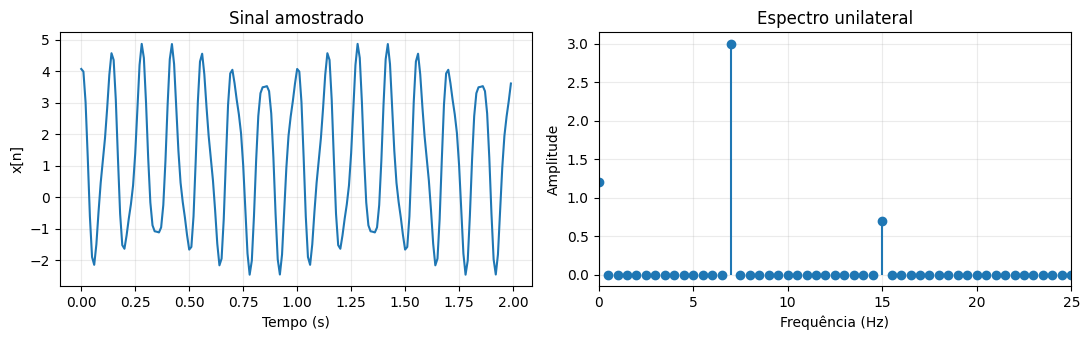

Nível médio: 1.2 | amplitude 7 Hz: 2.9999999999999996


In [2]:
import matplotlib.pyplot as plt
fs = 100.0                     # amostras por segundo
N = 200
n = np.arange(N)
t = n / fs
x = 1.2 + 3*np.cos(2*np.pi*7*t + 0.3) + 0.7*np.sin(2*np.pi*15*t)
freq = np.fft.rfftfreq(N, d=1/fs)  # frequências NÃO negativas (Hz)
Xr = np.fft.rfft(x)                # meia DFT para entradas reais
amp = 2*np.abs(Xr)/N
amp[0] = np.abs(Xr[0])/N           # DC não é duplicado
if N % 2 == 0:
    amp[-1] = np.abs(Xr[-1])/N    # Nyquist não é duplicado
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(t, x); ax[0].set(xlabel='Tempo (s)', ylabel='x[n]', title='Sinal amostrado')
ax[1].stem(freq, amp, basefmt=' '); ax[1].set(xlim=(0, 25), xlabel='Frequência (Hz)', ylabel='Amplitude', title='Espectro unilateral')
for q in ax: q.grid(alpha=.25)
plt.tight_layout(); plt.show()
print('Nível médio:', amp[0], '| amplitude 7 Hz:', amp[np.argmin(abs(freq-7))])
assert np.isclose(amp[0], 1.2, atol=1e-12)
assert np.isclose(amp[np.argmin(abs(freq-7))], 3.0, atol=1e-12)
assert np.isclose(amp[np.argmin(abs(freq-15))], 0.7, atol=1e-12)

**Interpretação da figura:** os picos em 7 e 15 Hz representam as amplitudes dos componentes presentes na amostra. O nível constante aparece no coeficiente de 0 Hz. O fato de a janela conter números inteiros de ciclos evita vazamento espectral neste exemplo particular.

### 7. Parseval discreto: dedução e conferência

Pela inversa, $x_n=\frac1N\sum_kX_k e^{i2\pi kn/N}$. Expandindo a energia:

$$\begin{aligned}
\sum_{n=0}^{N-1}|x_n|^2
&=\frac1{N^2}\sum_n\sum_k\sum_\ell X_k\overline{X_\ell}e^{i2\pi (k-\ell)n/N}\\
&=\frac1{N^2}\sum_k\sum_\ell X_k\overline{X_\ell}(N\delta_{k\ell})\\
&=\boxed{\frac1N\sum_{k=0}^{N-1}|X_k|^2}.
\end{aligned}$$

No exemplo de $N=4$, $\sum|x_n|^2=1+4+0+1=6$ e $\frac14\sum|X_k|^2=(4+10+0+10)/4=6$.

In [3]:
x = np.array([1., 2., 0., -1.])
X = np.fft.fft(x)
print('Energia temporal:', np.sum(np.abs(x)**2))
print('Energia frequencial:', np.sum(np.abs(X)**2)/len(x))
assert np.isclose(np.sum(abs(x)**2), np.sum(abs(X)**2)/len(x))

Energia temporal: 6.0
Energia frequencial: 6.000000000000001


Esta é uma identidade de **energia determinística de um vetor**. O periodograma estatístico (Módulo 9 e Morettin–Toloi, §14.4.2) usa normalização adicional e depende da unidade de frequência; não se deve identificar automaticamente $|X_k|^2$ com uma densidade espectral estatística.

### 8. Da integral contínua à soma discreta

Aproximando a integral em pontos $t_n=t_0+n\Delta t$:

$$F(\omega)\approx\Delta t\sum_{n=0}^{N-1}f(t_n)e^{-i\omega(t_0+n\Delta t)}.$$

Nas frequências $\omega_k=2\pi k/(N\Delta t)$, isso se torna

$$\boxed{F(\omega_k)\approx\Delta t\,e^{-i\omega_k t_0}X_k.}$$

Essa aproximação requer cautela: a DFT opera sobre uma janela **finita**, amostras **discretas** e frequências **discretas**. A fórmula inclui a fase de origem $t_0$ e o fator de escala $\Delta t$, frequentemente esquecidos na comparação com a transformada contínua.

### 9. Limitações: vazamento, aliasing e observação finita

- **Vazamento espectral (*spectral leakage*):** uma senoide cuja frequência não coincide com um bin da DFT espalha energia por vários bins da janela retangular.
- **Aliasing:** ao amostrar, frequências acima da frequência de Nyquist podem produzir valores indistinguíveis de frequências mais baixas.
- **Resolução:** a distância entre bins é $1/(N\Delta t)$; acrescentar zeros (*zero padding*) interpola a grade, mas não cria observações nem aumenta a resolução física efetiva.
- **Estatística:** um pico pode ser artefato, ruído ou oscilação genuína; a DFT isolada não fornece um teste de significância.

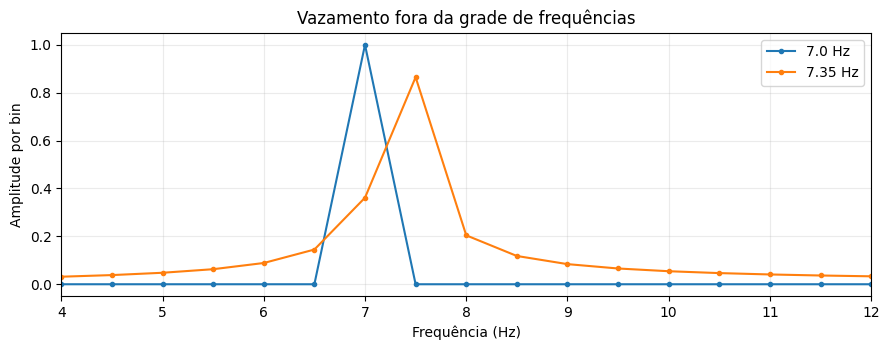

In [4]:
# Compare uma frequência exatamente no bin com outra fora da grade
fs = 100; N = 200
n = np.arange(N); t = n/fs
fig, ax = plt.subplots(figsize=(9, 3.6))
for hz in [7.0, 7.35]:
    x = np.cos(2*np.pi*hz*t)
    A = 2*np.abs(np.fft.rfft(x))/N
    ax.plot(np.fft.rfftfreq(N, 1/fs), A, '-o', ms=3, label=f'{hz} Hz')
ax.set(xlim=(4, 12), xlabel='Frequência (Hz)', ylabel='Amplitude por bin', title='Vazamento fora da grade de frequências')
ax.legend(); ax.grid(alpha=.25); plt.tight_layout(); plt.show()

**Interpretação da figura:** 7 Hz coincide com um bin (resolução de $0{,}5$ Hz); 7,35 Hz não coincide, por isso sua energia se distribui entre bins. Não se trata de aparecimento de novas frequências físicas.

### 10. Exercícios orientados

1. **À mão:** obtenha a DFT de $x=(1,0,-1,0)$ para $N=4$, mostrando cada exponencial complexa.
2. A partir da prova de ortogonalidade, derive novamente a inversa sem consultar a seção 4.
3. Calcule a DFT de um vetor de oito uns. Explique por que apenas $X_0$ é diferente de zero.
4. **Pseudocódigo:** escreva dois laços aninhados que implementem a definição da DFT; conte as operações aproximadamente e compare o custo $O(N^2)$ com o da FFT $O(N\log N)$, assunto da Seção 8.7.
5. A uma taxa de amostragem de 40 Hz, qual a frequência de Nyquist? Uma senoide de 27 Hz seria distinguível de uma de 13 Hz em amostras igualmente espaçadas? Justifique com a fórmula dos cossenos.
6. Refaça o gráfico de vazamento usando janelas de 2 e 4 segundos. Distinga resolução de frequência e *zero padding*.

### Referências

- MORETTIN, P. A.; TOLOI, C. M. C. *Análise de séries temporais: modelos lineares univariados*. 3. ed. São Paulo: Blucher, 2018. v. 1, cap. 13, §13.4, pp. 348–350; cap. 14, §14.4.1, pp. 367–369 e §14.4.2, pp. 369–373. **Consulta direta às páginas indicadas.**
- As demonstrações detalhadas da inversa, ortogonalidade e Parseval discreto, e o código em NumPy, são desenvolvimento didático complementar sob a convenção de normalização explicitada na Seção 2.